In [35]:
from pathlib import Path 
import pandas as pd
import geopandas as gpd
from shapely.geometry import Polygon, LineString
import matplotlib.pyplot as plt

In [19]:
path = Path.cwd()

In [20]:
anchorage_areas = gpd.read_file(path / 'anchorage_area.geojson')
anchorage_areas = anchorage_areas[anchorage_areas.geometry.geom_type != "Point"]
anchorage_areas["geometry"] = anchorage_areas.geometry.apply(
    lambda geom: Polygon(geom) if geom.geom_type == "LineString" and geom.is_ring else geom
)

In [26]:
separation_zones = gpd.read_file(path / 'separation_zone.geojson')
separation_zones = separation_zones[separation_zones.geometry.geom_type != "Point"]
separation_zones["geometry"] = separation_zones.geometry.apply(
    lambda geom: Polygon(geom) if geom.geom_type == "LineString" and geom.is_ring else geom
)

In [31]:
separation_boundaries = gpd.read_file(path / 'separation_boundary.geojson')

In [36]:
precaution_areas = gpd.read_file(path / 'precaution_area.geojson')
precaution_areas["geometry"] = precaution_areas.geometry.apply(
    lambda geom: LineString(geom.exterior.coords)
    if geom.geom_type == "Polygon"
    else geom
)

<Axes: >

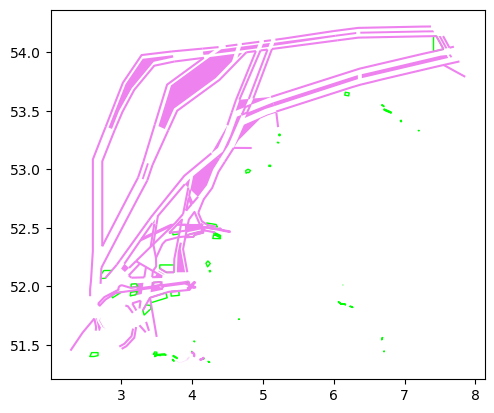

In [40]:
fig, ax = plt.subplots()
separation_zones.plot(ax=ax, color='violet')
separation_boundaries.plot(ax=ax, color='violet')
anchorage_areas.plot(ax=ax, edgecolor = 'lime', color='none')

<Axes: >

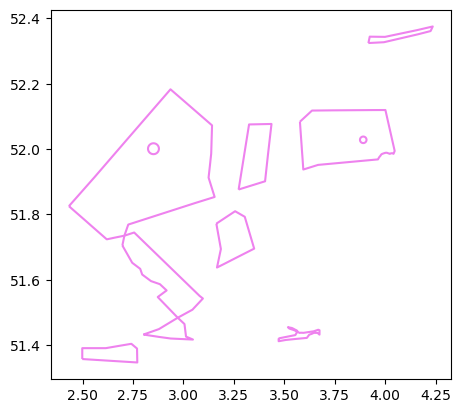

In [38]:
fig,ax = plt.subplots()
